# 02 — Exploratory Data Analysis

## What this notebook covers
- Deleting the 182 duplicated rows when ignoring the ID
- Spliting the data (we're gonna take 80% for training and 20% for tests, with 5 cross folds)
- Distribution of variables 
- Correlation with the target
- Ideas about new features

### Note
We will proceed the eda just on training set to avoid ***data snooping bias***

### Loading packages

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import seaborn as sns
import math
import matplotlib.pyplot as plt
import numpy as np



PROJECT_ROOT = Path.cwd().parent        # .cwd() gives the directory notebooks/ and so .parent gives the root
sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import remove_duplicate_customers, split_data, save_splits
from src.config import TARGET, ID_COL, DATE_COL, NUMERICAL_COLS, FIGURES_DIR, CATEGORICAL_COLS, PAST_CAMPAIGN_COLS
from src.data_loader import load_marketing_campaign, load_processed


marketing_df = load_marketing_campaign()

**Deleting the 182 duplicates**

In [2]:
n_before = len(marketing_df)
marketing_df = remove_duplicate_customers(marketing_df)
print(f"Removed {n_before - len(marketing_df)} duplicates -> {len(marketing_df)} customers")
print(f"Response rate: {marketing_df[TARGET].mean():.3f}")

Removed 182 duplicates -> 2058 customers
Response rate: 0.152


**Re-checking**

In [3]:
n_dup_without_id = marketing_df.drop(columns=ID_COL).duplicated().sum()
print(f"Duplicated rows when ignoring ID: {n_dup_without_id}")

Duplicated rows when ignoring ID: 0


**Spliting the data**

In [4]:
train_df, test_df = split_data(marketing_df)
print("train size : ", len(train_df))
print("test size : ", len(test_df))
print(train_df[TARGET].mean(), test_df[TARGET].mean())       

train size :  1646
test size :  412
0.15188335358444716 0.1529126213592233


**Saving train and test datasets**

In [5]:
save_splits(train_df, test_df)

**loading the training set to proceed the EDA**

In [6]:
train = load_processed("train")
print(train[DATE_COL].dtype)

datetime64[us]


**Variables distribution**

*Numerical variables*

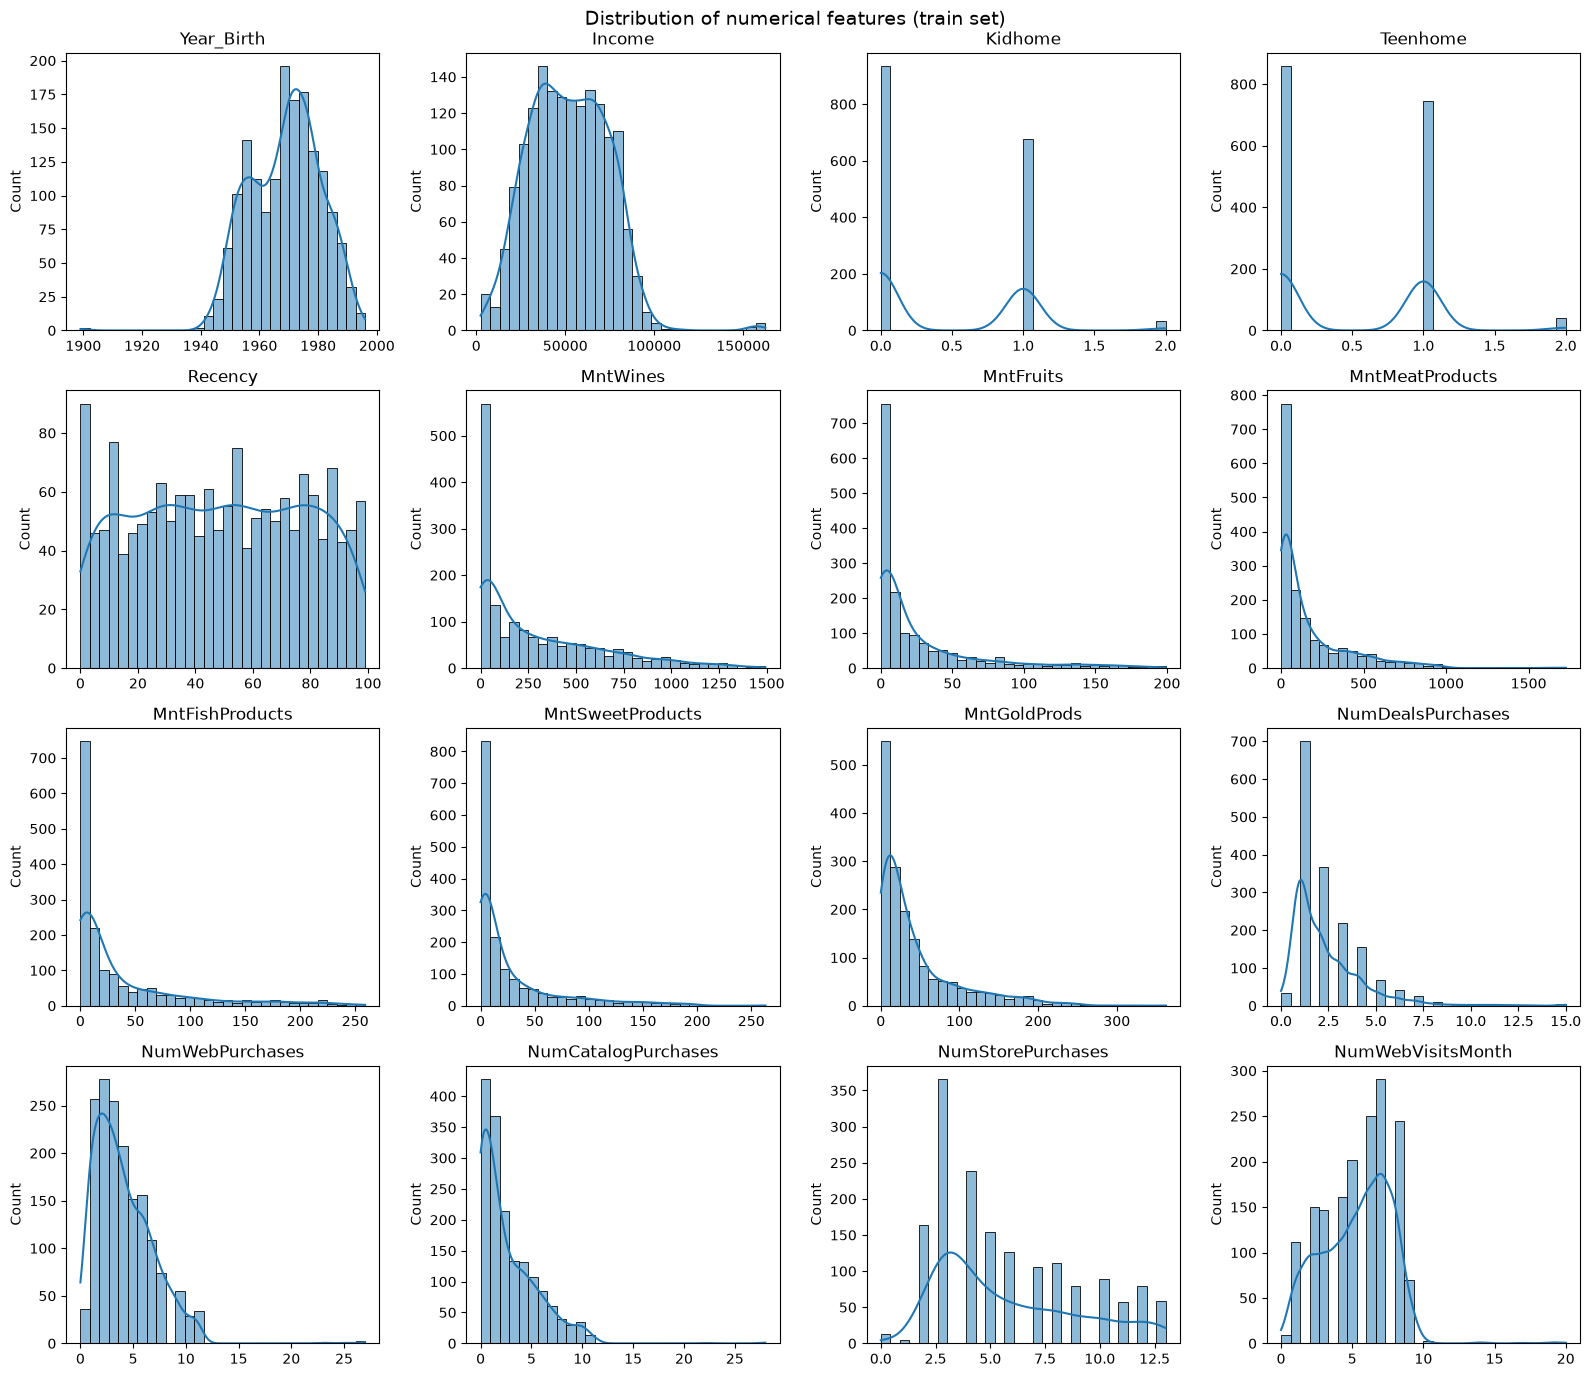

In [7]:
n_cols = 4
n_rows = math.ceil(len(NUMERICAL_COLS) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.flatten()                      # grid -> flat list, one ax per variable

for ax, col in zip(axes, NUMERICAL_COLS):
    sns.histplot(data=train, x=col, bins=30, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

for ax in axes[len(NUMERICAL_COLS):]:      # hide unused subplots
    ax.set_visible(False)

fig.suptitle("Distribution of numerical features (train set)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "numerical_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

*Note* : 
Even if the variables Kidhome and Teenhome are numerical for the model, but for a better vizualisation, a countplot will be much better than hisplot

*Testing the symetry of the variables : < 0,5 -> quasi-symetrical ;between 0,5 and 1 -> moderate asymetry; >1 -> asymetrical*

In [8]:
skew = train[NUMERICAL_COLS].skew().sort_values(ascending=False)
skew

NumDealsPurchases      2.420979
MntSweetProducts       2.158113
MntFruits              2.137984
MntMeatProducts        2.116350
MntFishProducts        1.993557
NumCatalogPurchases    1.897764
MntGoldProds           1.886403
NumWebPurchases        1.603158
MntWines               1.210799
NumStorePurchases      0.707832
Kidhome                0.588134
Teenhome               0.443594
Income                 0.391800
NumWebVisitsMonth      0.123173
Recency               -0.003026
Year_Birth            -0.308646
dtype: float64

**Observations**
- The `Mnt*` variables and `NumWebPurchases`, `NumCatalogPurchases`, `NumDealsPurchases` are strongly right-skewed (skew > 1): many small values and a long tail of large ones. They also contain zeros.
- `Recency` is roughly uniform, `Year_Birth`, `Income` and `NumWebVisitsMonth` are close to symmetric (|skew| < 0.5).
- `Income` has a low skew (0.39) in the training set: the extreme value of 666666 seen in notebook 01 is not in the train set (checked below).

**Hypothesis:** a `log1p` transformation of the skewed variables *may* help the Logistic Regression (it compresses the extreme values that would otherwise dominate the coefficients). Tree-based models do not need it, since they only use the order of the values.

**Decision:** compare Logistic Regression with and without `log1p` in notebook 04, using stratified cross-validation (PR-AUC). The transformation is kept only if it improves the score.

In [9]:
# Where did the extreme values seen in notebook 01 end up?
print("Max Income in train:", train["Income"].max())
print("Min Year_Birth in train:", train["Year_Birth"].min())
print("Customers born before 1920 in train:", (train["Year_Birth"] < 1920).sum())

Max Income in train: 162397.0
Min Year_Birth in train: 1899
Customers born before 1920 in train: 2


**Observation:** the income of 666666 is in the **test set**, not in the train set (max income in train: 162397). On the other hand, **2 customers** with an impossible birth year (before 1920, minimum 1899) are in the train set.

**Decision:** outlier handling must be part of the preprocessing pipeline (applied to both train and test with rules defined on train), not a one-off cleaning of the training data: the same kind of value can reach the model in production.

*Categorical and binary variables*

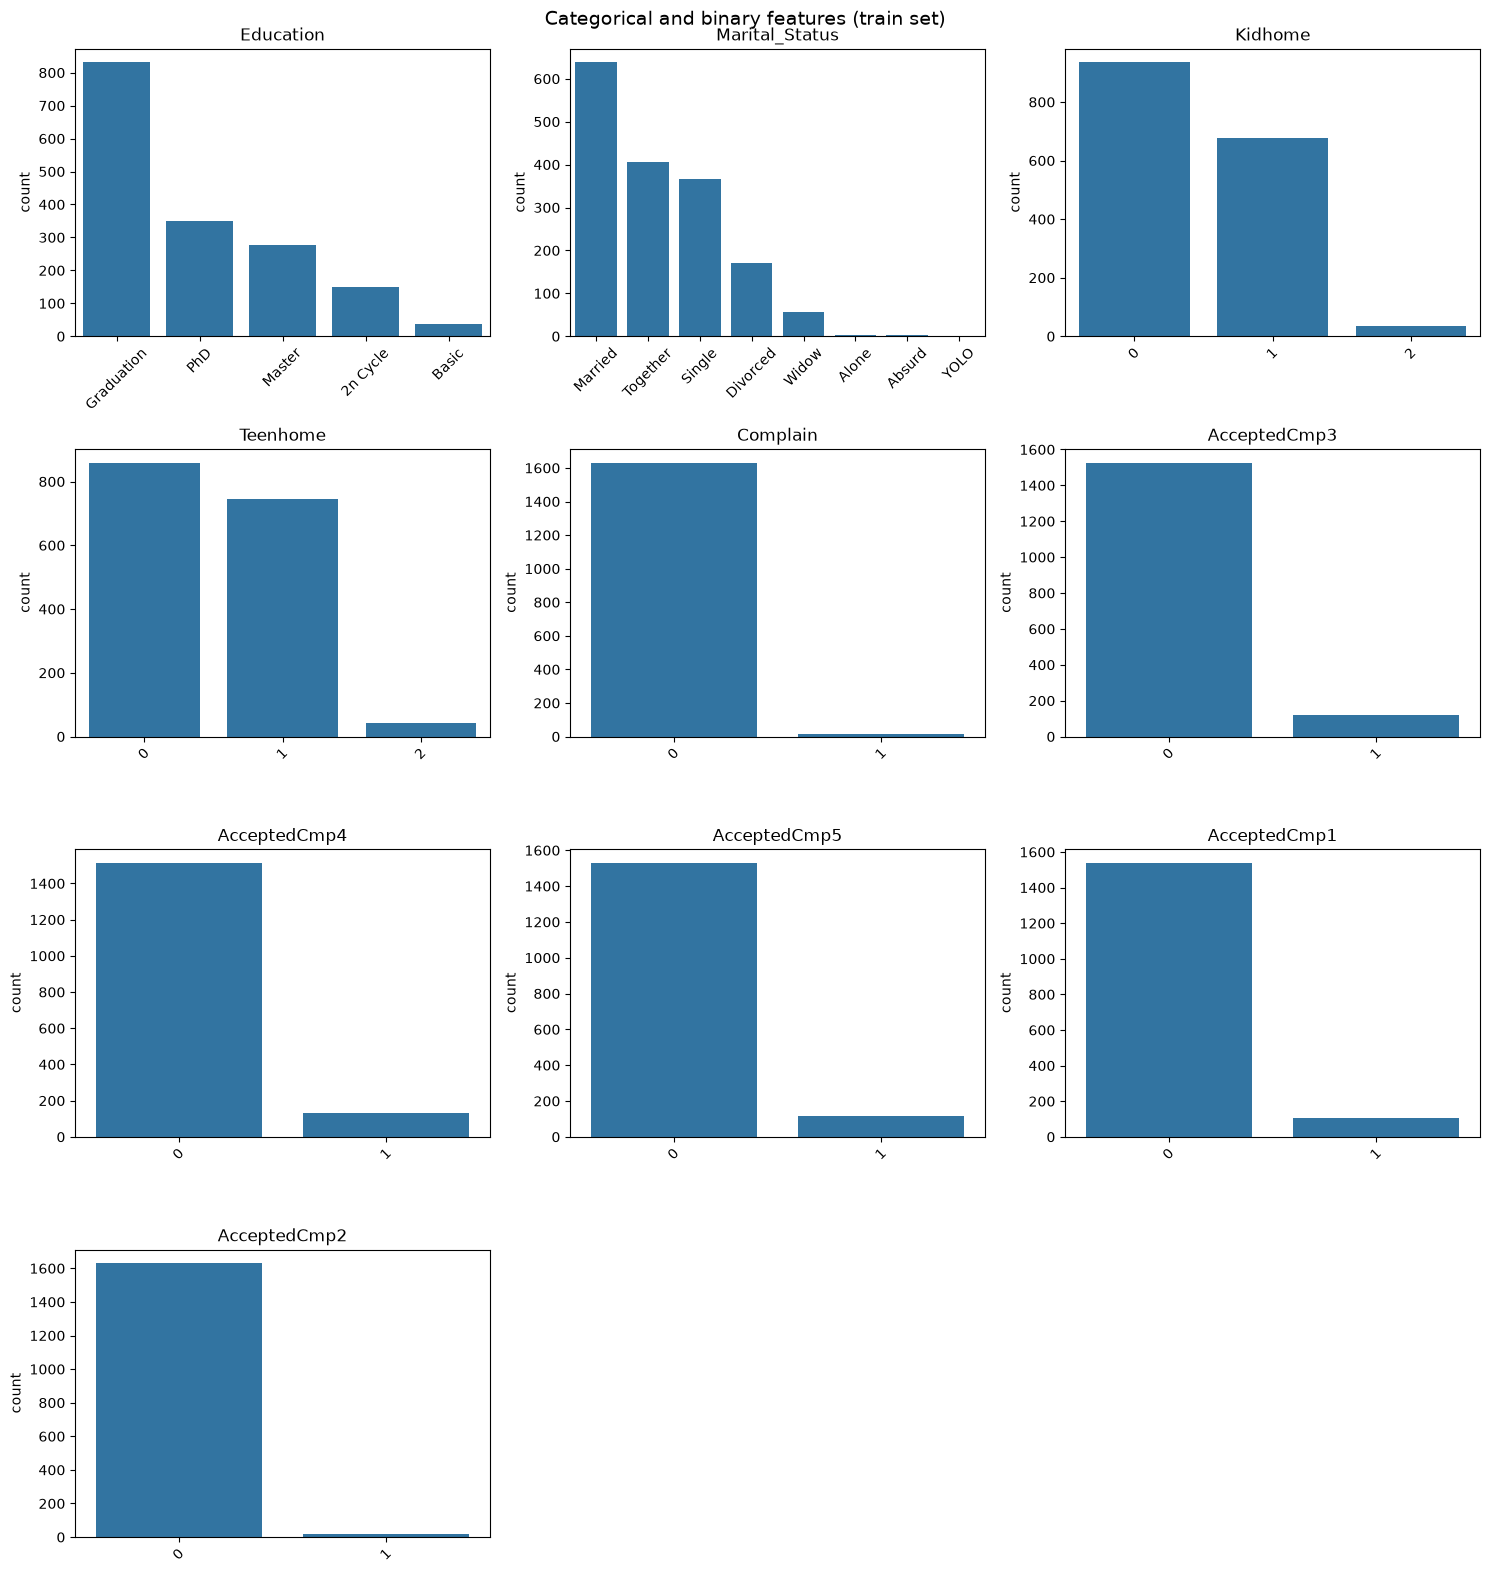

In [10]:
cat_bin_vars = CATEGORICAL_COLS + ['Kidhome', 'Teenhome','Complain'] + PAST_CAMPAIGN_COLS

n_cols = 3
n_rows = math.ceil(len(cat_bin_vars) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_bin_vars):
    order = train[col].value_counts().index          # bars sorted from most to least frequent
    sns.countplot(data=train, x=col, order=order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)            # readable labels for Marital_Status

for ax in axes[len(cat_bin_vars):]:
    ax.set_visible(False)

fig.suptitle("Categorical and binary features (train set)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "categorical_counts.png", dpi=150, bbox_inches="tight")
plt.show()



*Response rate by category*

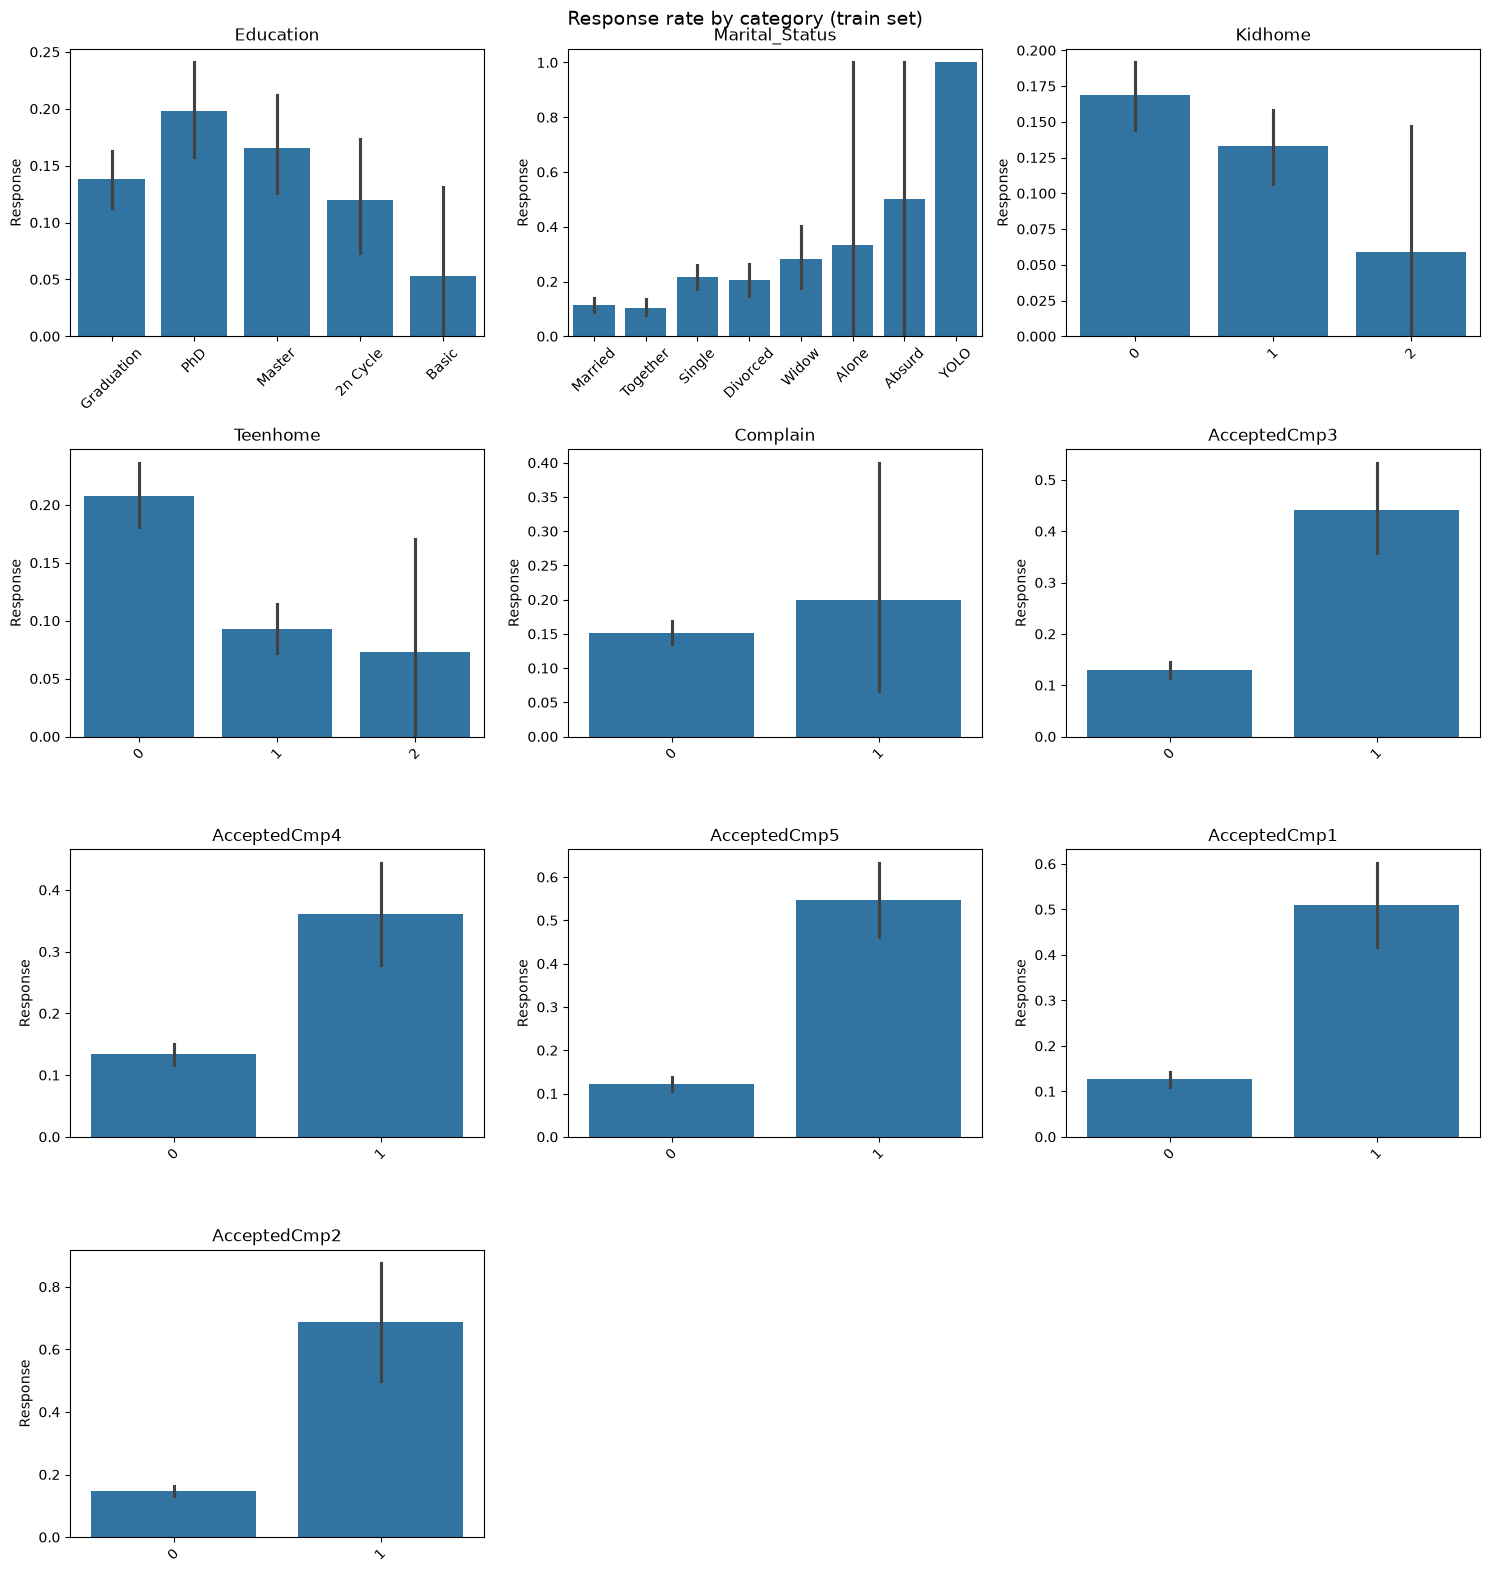

In [11]:
n_cols = 3
n_rows = math.ceil(len(cat_bin_vars) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_bin_vars):
    order = train[col].value_counts().index          # bars sorted from most to least frequent
    sns.barplot(data=train, x=col, y=TARGET, order=order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)            # readable labels for Marital_Status

for ax in axes[len(cat_bin_vars):]:
    ax.set_visible(False)

fig.suptitle("Response rate by category (train set)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "response_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()



**Observations** (response rate = height of the bar; the black lines are 95% confidence intervals)
- **Past campaigns are the strongest signal:** customers who accepted a previous campaign respond at 35–70%, versus ~13% for the others.
- **Children reduce the response rate**, especially teenagers: ~21% with no teenager at home vs ~9% with one.
- **Single, divorced and widowed customers respond about twice as often** as couples (`Married`, `Together`).
- **Education:** `PhD` has the highest response rate (~20%), `Basic` the lowest (~5%).
- `Complain` shows no clear difference (very wide interval: only ~1% of customers complained).
- `YOLO`, `Absurd` and `Alone` look extreme but rely on 1–3 customers: their huge intervals show these rates are **not reliable**.

**Ideas for feature engineering:**
- Group `Marital_Status` into two levels: *living alone* (Single, Divorced, Widow, Alone, YOLO, Absurd) vs *in couple* (Married, Together).
- Group `Education` into fewer levels (e.g. merge `2n Cycle` with `Master`).
- Create `children = Kidhome + Teenhome` and/or `has_children`.
- Create `total_accepted_cmp` = sum of the 5 past campaigns.

*Correlation with the target*

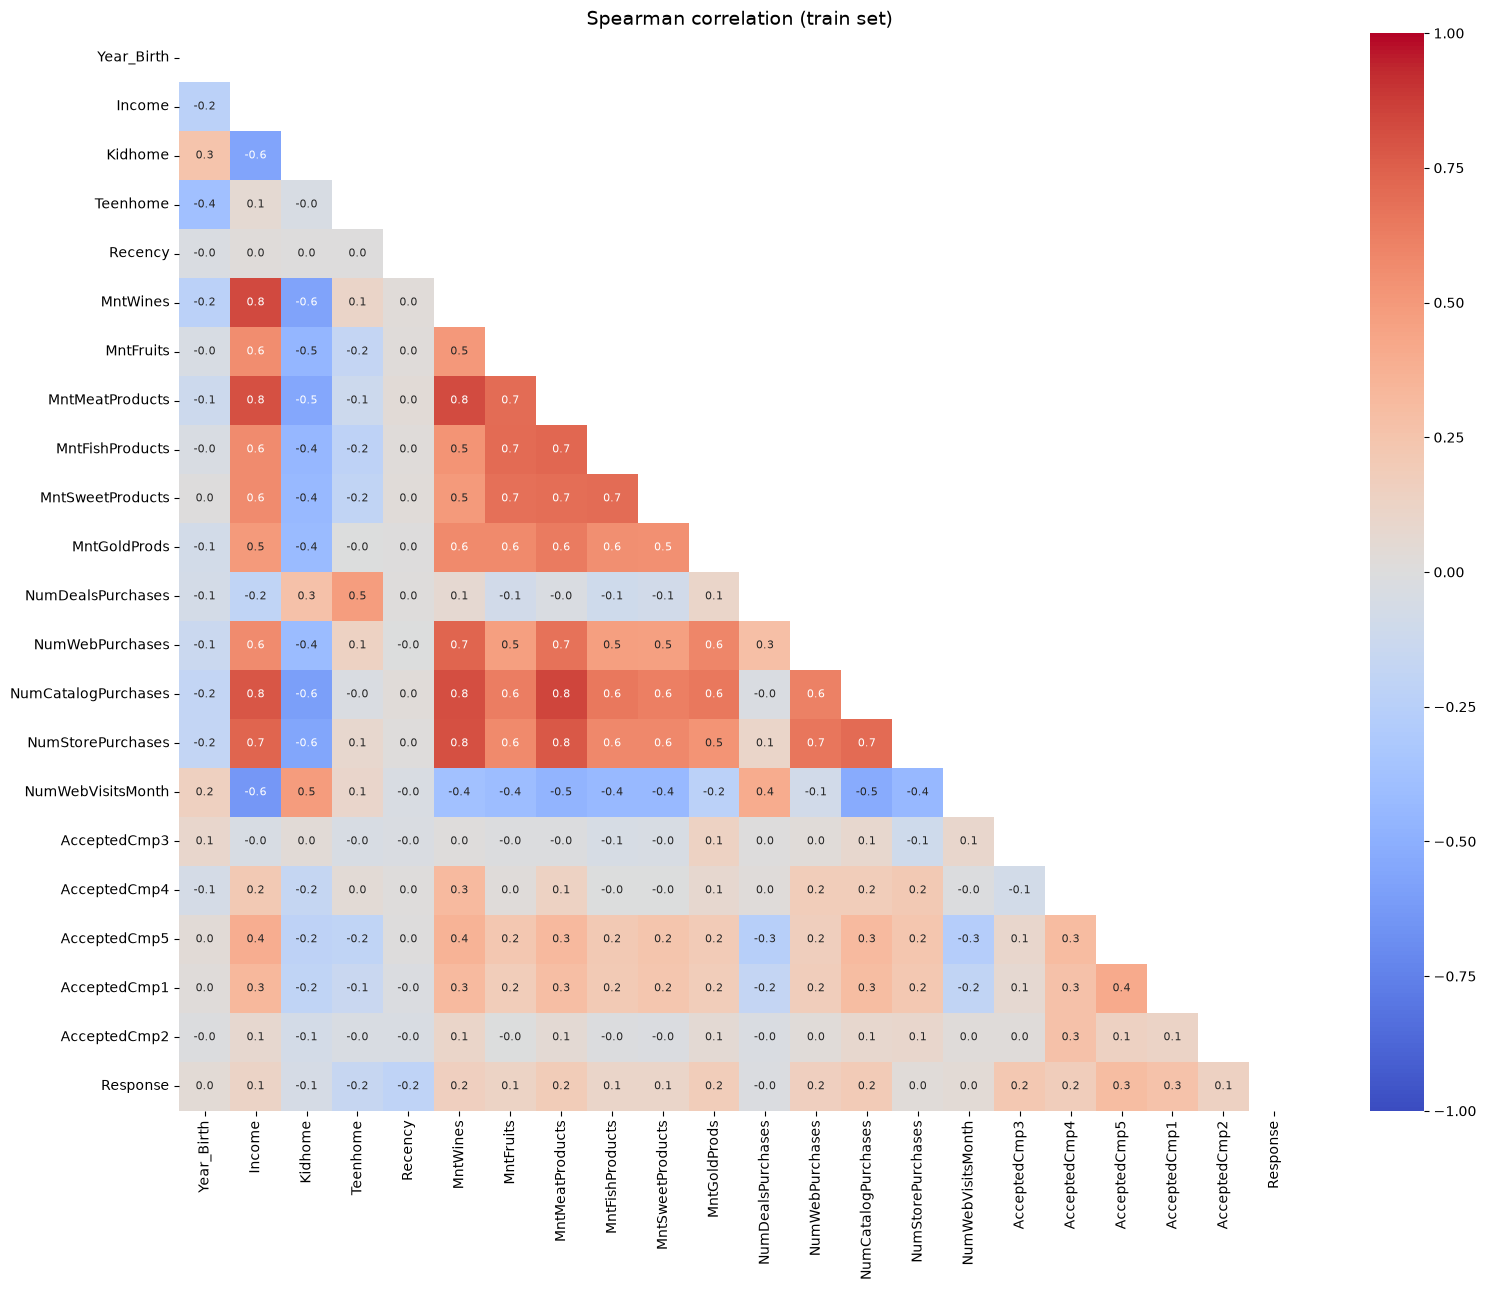

In [12]:
corr_cols = NUMERICAL_COLS + PAST_CAMPAIGN_COLS + [TARGET]
corr = train[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the upper triangle (duplicate)

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, mask=mask, annot=True, fmt=".1f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation (train set)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations (correlations between features)**
- A large block of strongly correlated variables: `Income`, the `Mnt*` amounts and the purchase counts (`NumCatalogPurchases`, `NumStorePurchases`, `NumWebPurchases`), with Spearman correlations up to 0.8 (e.g. `Income`–`MntWines`, `MntMeatProducts`–`NumCatalogPurchases`). They all describe the same thing: **how much the customer buys**.
- `Kidhome` and `NumWebVisitsMonth` are negatively correlated with income and spending (around -0.5 / -0.6).

**Decision:** this multicollinearity can make the Logistic Regression coefficients unstable and hard to interpret (not its predictions). Options for notebook 03/04: a `total_spent` feature, regularisation (L2), or keeping only part of the block. Tree-based models are not affected.

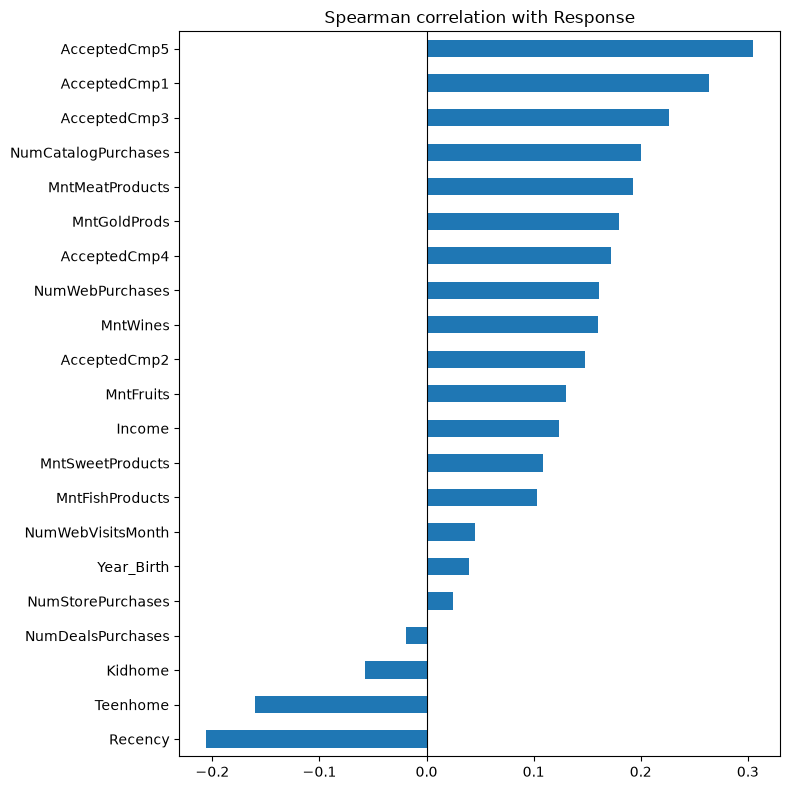

In [13]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
ax = target_corr.plot(kind="barh", figsize=(8, 8), title="Spearman correlation with Response")
ax.axvline(0, color="black", linewidth=0.8)        # reference line at 0
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_with_target.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations (link with `Response`)**
- Strongest positive links: past campaigns (`AcceptedCmp5`, `AcceptedCmp1`, `AcceptedCmp3`), then `NumCatalogPurchases`, `MntMeatProducts`, `MntGoldProds`, `MntWines`.
- Strongest negative links: `Recency` (≈ -0.2, the longer since the last purchase, the less likely to respond) and `Teenhome`.
- Almost no link: `NumDealsPurchases`, `NumStorePurchases`, `Year_Birth`, `NumWebVisitsMonth`.
- All correlations stay below 0.31: no single variable predicts the response on its own, and no suspiciously perfect correlation (no leakage signal).

> Spearman only measures monotonic relationships one variable at a time; a variable with a weak correlation can still be useful in combination with others.

*Numerical variables: responders vs non-responders*

In [14]:
# Median of each numerical variable for each class (median: robust to skewed distributions)
medians = train.groupby(TARGET)[NUMERICAL_COLS].median().T
medians.columns = ["no_response (0)", "response (1)"]
medians["ratio_1_vs_0"] = (medians["response (1)"] / medians["no_response (0)"]).round(2)
medians

,no_response (0),response (1),ratio_1_vs_0
Year_Birth,1970.0,1971.0,1.00
Income,50437.0,58138.0,1.15
Kidhome,0.0,0.0,NaN
Teenhome,1.0,0.0,0.00
Recency,52.0,28.5,0.55
MntWines,155.5,334.5,2.15
MntFruits,7.0,17.5,2.50
MntMeatProducts,59.0,139.0,2.36
MntFishProducts,11.0,21.0,1.91
MntSweetProducts,7.0,18.0,2.57


**Observations** (ratio = median of responders / median of non-responders)
- **Spending:** responders spend about **2 to 2.6 times more** in every `Mnt*` category (wines 334 vs 156, meat 139 vs 59, sweets 18 vs 7). This supports a `total_spent` feature.
- **Purchase channels:** responders make **3 times more catalog purchases** (3 vs 1) and more web purchases (5 vs 3), but the same number of store purchases (5 vs 5). The channel matters, not only the volume.
- **Recency:** responders bought much more recently (median 28.5 vs 52 days, ratio 0.55), consistent with the negative correlation seen above.
- **Household:** the median responder has **no teenager at home** (0 vs 1), consistent with the response-rate plots. `Kidhome` gives `NaN` because both medians are 0 (0 / 0): the median is not informative for a variable that is mostly 0, the response rate by modality (above) is the right view.
- **Income** is only slightly higher for responders (+15%), and slightly fewer deal purchases (1.5 vs 2).
- **No difference:** `Year_Birth` (age), `NumStorePurchases` and `NumWebVisitsMonth` have identical medians. This does not prove they are useless (the median ignores the rest of the distribution and interactions), but they are unlikely to be strong predictors on their own.

*Customer tenure*

`Dt_Customer` cannot be used raw. We convert it into a **tenure in days**, relative to the most recent enrolment date **of the training set** (never `today()`, which would change every time the code runs).

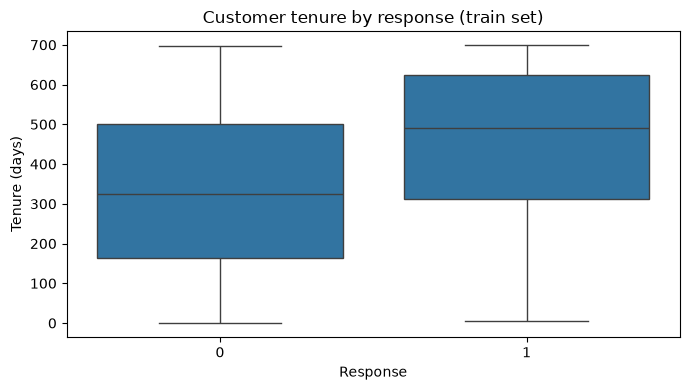

Reference date: 2014-06-29
Response
0    324.5
1    492.0
Name: Dt_Customer, dtype: float64


In [15]:
reference_date = train[DATE_COL].max()
tenure_days = (reference_date - train[DATE_COL]).dt.days

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x=train[TARGET], y=tenure_days, ax=ax)
ax.set_xlabel("Response")
ax.set_ylabel("Tenure (days)")
ax.set_title("Customer tenure by response (train set)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tenure_by_response.png", dpi=150, bbox_inches="tight")
plt.show()

print("Reference date:", reference_date.date())
print(tenure_days.groupby(train[TARGET]).median())

**Observation:** responders have been customers **for longer**: median tenure of **492 days** vs **324.5 days** for non-responders (reference date: 2014-06-29). The whole box is shifted up (Q1 ≈ 310 vs 165 days), so it is not driven by a few customers. The ranges overlap a lot, so tenure is a useful but not decisive signal.

**Decision:** create a `tenure_days` feature in notebook 03. The reference date is taken from the training set and reused as is for the test set (no leakage).

---
## Conclusion

| # | Observation | Action in notebook 03 / 04 |
|---|---|---|
| 1 | Past campaigns are the strongest signal | Keep the 5 columns + create `total_accepted_cmp`; business-rule baseline in notebook 04 |
| 2 | `Recency` is negatively linked to the response | Keep as is |
| 3 | Children (especially teenagers) reduce the response | Create `children` / `has_children` |
| 4 | Singles respond about twice as often as couples | Group `Marital_Status` into *alone* vs *couple* |
| 5 | Rare and meaningless categories (`YOLO`, `Absurd`, `Alone`, `Basic`) | Regroup before encoding |
| 6 | `Mnt*` and purchase counts strongly right-skewed (skew > 1) | Test `log1p` for Logistic Regression only (with vs without, notebook 04) |
| 7 | Strong correlation block: income, spending, purchases | Create `total_spent`; use L2 regularisation for Logistic Regression |
| 8 | Income outlier (666666) in the test set, impossible birth years in train | Outlier rules inside the preprocessing pipeline, defined on train |
| 9 | 24 missing `Income` values | Median imputation fitted on train, inside the `Pipeline` |
| 10 | `Dt_Customer` not usable raw | Create `tenure_days` (reference date from train) and `age` |
| 11 | `Complain`, `NumDealsPurchases` show almost no link | Keep for now; check their importance with SHAP later |

**Next step:** notebook 03 — feature engineering, built as reusable functions in `src/features.py` and a scikit-learn `Pipeline`.